# COU 07506 Digital Signal Processing — Week 01: Lab 0 — Setting Up the DSP Laboratory

- **Name:** Faida Sylivester Mosses
- **Registration No.:** 240647474625
- **Class:** BEng24ETE (Stream 2)
- **Group:** 09
- **Date:** 25 November 2026
- **Instructor checkpoints signed:** [ ] 1

### Pre-lab question (Lab 0)
*List three devices you used today that contain DSP, and for each name one signal it processes.*

**Answer.**
1. **Smartphone:** I recorded my voice on it today. It processes my voice (the microphone signal): it samples the sound into numbers and compresses it before saving the voice note.
2. **Wi-Fi router:** it processes the radio signal that carries my internet data. DSP is used to send the data and to recover it from the received radio signal.
3. **Laptop:** I played music on it. It processes the digital audio signal of the song: it decodes the compressed audio, and a DAC converts the numbers into the analogue signal sent to the speakers or headphones.

### Task 1.1 —  first notebook (Lab 0)
Load the standard libraries used in every lab.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

#### Task 1.1(a) — Create the elementary sequences (Lab 0)
Build δ(n), u(n), r(n) and (0.8)^n u(n) as arrays, and print them.

In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = 0.8**n * step

print("n     =", n)
print("delta =", delta)
print("step  =", step)
print("ramp  =", ramp)
print("expo  =", np.round(expo, 3))

n     = [-5 -4 -3 -2 -1  0  1  2  3  4  5  6  7  8  9 10]
delta = [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
step  = [0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
ramp  = [-0. -0. -0. -0. -0.  0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
expo  = [0.    0.    0.    0.    0.    1.    0.8   0.64  0.512 0.41  0.328 0.262
 0.21  0.168 0.134 0.107]


#### Task 1.1(b) — Plot the elementary sequences (Lab 0)
Draw δ(n), u(n), r(n) and (0.8)^n u(n) as stem plots.


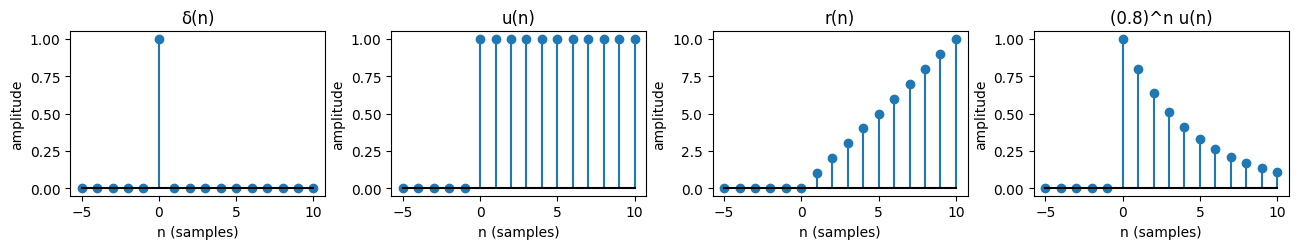

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n (samples)")
    ax.set_ylabel("amplitude")
plt.tight_layout()
plt.show()

### Task 1.2 — Change the parameters (Lab 0)
Part 1: plot (a)^n u(n) for a = 0.5, −0.8 and 1.1.

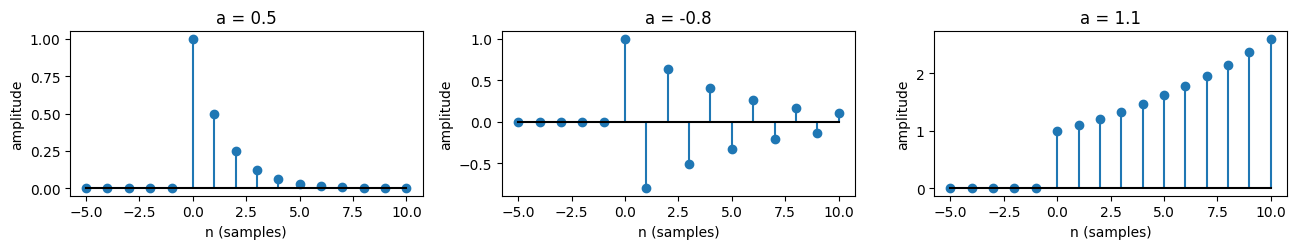

In [4]:
a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 2.6))
for ax, a in zip(axes, a_values):
    x = a**n * step
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n (samples)")
    ax.set_ylabel("amplitude")
plt.tight_layout()
plt.show()

#### Task 1.2 — Part 2: two cosines (Lab 0)
Plot cos(2πn/8) and cos(2πn/7.5) for 0 ≤ n ≤ 40.

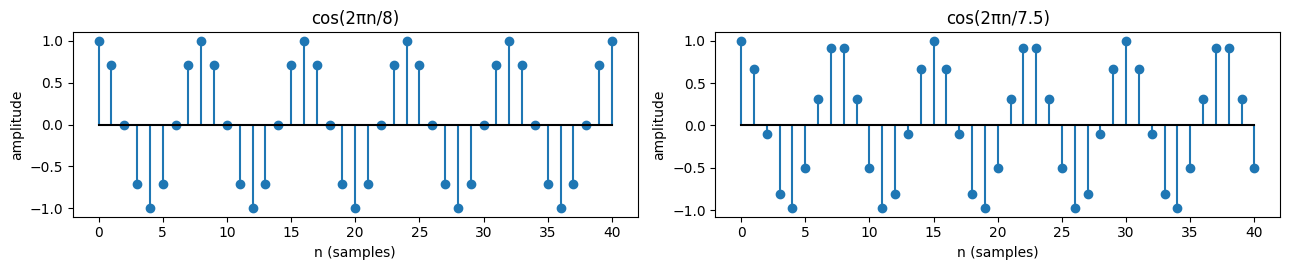

In [5]:
n2 = np.arange(0, 41)
x1 = np.cos(2*np.pi*n2/8)
x2 = np.cos(2*np.pi*n2/7.5)

fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
for ax, x, title in zip(axes, [x1, x2], ["cos(2πn/8)", "cos(2πn/7.5)"]):
    ax.stem(n2, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n (samples)")
    ax.set_ylabel("amplitude")
plt.tight_layout()
plt.show()

#### Task 1.3(a) — Convert the recording to WAV (Lab 0)
WhatsApp saved my voice as .mp4 (AAC audio). Convert it to .wav so Python can read it.

In [6]:
!pwd
!ffmpeg -y -i /my_voice.mp4 -ac 1 /content/my_voice.wav
!ls -l /my_voice.mp4 /content/my_voice.wav

/content
ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libz

#### Task 1.3(b) — Read the audio file and plot it (Lab 0)
Load my_voice.wav, print its sampling rate and duration, and plot the waveform.

fs = 44100 Hz, duration = 5.76 s, samples = 253952


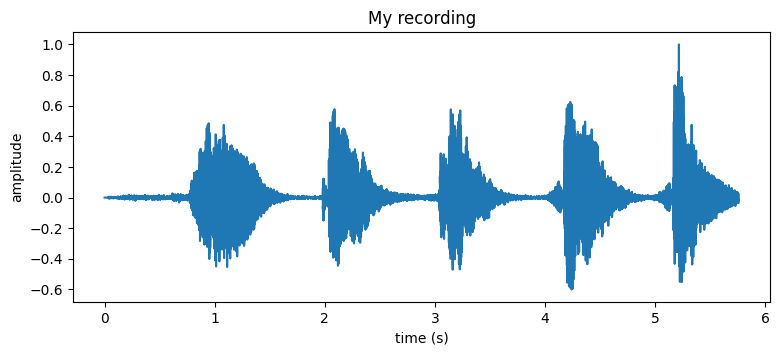

In [7]:
import os
fname = "my_voice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))
else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)
t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording")
plt.show()

### Analysis questions (Lab 0)
**Q1.** What is the sampling rate of my phone's recording? How many numbers are needed to store one minute of it in mono?

In [8]:
numbers_per_minute = fs * 60
print(f"Sampling rate fs = {fs} Hz")
print(f"Numbers needed for one minute (mono) = {numbers_per_minute}")

Sampling rate fs = 44100 Hz
Numbers needed for one minute (mono) = 2646000


**Answer 1.** The sampling rate of my recording is 44,100 Hz (printed by the code above), which means 44,100 numbers are stored for every second of sound. One minute is 60 seconds, so a mono recording needs 44,100 × 60 = 2,646,000 numbers.

**Q2.** Why is a stem plot more appropriate than a continuous line for x(n)?

**Answer 2.** A discrete-time signal x(n) exists only at whole-number values of n; there is no value between n = 2 and n = 3. A stem plot draws one separate vertical line and dot for each sample, so it shows exactly the values that exist. A continuous line would join the points and wrongly suggest that the signal has values in between (see the stem plots in Task 1.1).

**Q3.** For a = 1.1 the exponential grows. Which property of a system would such a signal violate if it were an impulse response (Unit 1 §1.7)?

**Answer 3.** It would violate **stability**. An LTI system is BIBO stable (a bounded input always gives a bounded output) only if its impulse response is absolutely summable, that is, Σ|h(n)| < ∞. For h(n) = (1.1)^n u(n) the samples keep growing (see the a = 1.1 plot in Task 1.2), so the sum is infinite and the system is unstable. Even a small bounded input could give an output that grows without limit. For comparison, a = 0.5 shrinks, its sum is finite, and that system is stable.

### AI-use statement
- **AI tools used:** Claude (Anthropic chat assistant).
- **Used for:** step-by-step guidance and explanations of the Lab 0 code (imports, elementary sequences, stem plots, reading and plotting audio); converting my WhatsApp voice note to WAV with ffmpeg; suggesting wording for my pre-lab and analysis answers, which I then rewrote in my own words.
- **How I verified the output:** I ran every cell and checked the Task 1.1 plots against the expected result in the lab manual, and the other plots against what the formulas predict. I checked that the sampling rate (44,100 Hz) and duration (5.76 s) printed by Python match what ffmpeg reported for the file. I checked 44,100 × 60 = 2,646,000 by hand, and I checked the stability answer against handout §1.7.5.
